# Actividad 13. Integración de la predicción en la aplicación

Los modelos se exportan a un único archivo JSON y la inferencia ocurre **en el
navegador**. No hay servidor de machine learning, no se envían datos a
internet y la pestaña **Predecir** funciona incluso sin conexión.

Esta actividad comprueba cuatro cosas:

1. que el paquete exportado tenga todo lo necesario;
2. que la inferencia en JavaScript coincida con la de Python;
3. que las métricas publicadas sean las de prueba;
4. que la interfaz esté documentada y sea accesible.

## 1. Configuración

In [1]:
import json
import math
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados" / "ml"
GRAFICAS = RAIZ / "resultados" / "graficas" / "ml"
TABLAS = RAIZ / "resultados" / "tablas"
for carpeta in (RESULTADOS, GRAFICAS, TABLAS):
    carpeta.mkdir(parents=True, exist_ok=True)

PALETA = {
    "purpura": "#4C1D95",
    "purpura_claro": "#8B5CF6",
    "rosa": "#FA8A9A",
    "amarillo": "#FFB71B",
    "rojo": "#EE3E29",
    "coral": "#FF8A5F",
    "azul": "#1B4576",
    "gris": "#7A7191",
}
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "font.family": "DejaVu Sans",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.22,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    }
)


def guardar(fig, nombre):
    ruta = GRAFICAS / nombre
    fig.savefig(ruta, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"Figura guardada: {ruta.relative_to(RAIZ)}")

In [2]:
PAQUETE = RAIZ / "app" / "modelos" / "modelo_prediccion.json"
paquete = json.loads(PAQUETE.read_text(encoding="utf-8"))
tamano_mb = PAQUETE.stat().st_size / (1024 * 1024)

print(f"Paquete: {PAQUETE.relative_to(RAIZ)}")
print(f"Tamaño: {tamano_mb:.2f} MB")
print(f"Versión: {paquete['version']} · generado: {paquete['generado']}")
print(f"Países: {len(paquete['catalogo']['paises'])}")
print(f"Tipos de desastre: {len(paquete['catalogo']['tipos'])}")
print(f"Variables one-hot para XGBoost: {len(paquete['esquema']['columnas_xgb'])}")

Paquete: app\modelos\modelo_prediccion.json
Tamaño: 3.07 MB
Versión: 1 · generado: 2026-11-26 11:44
Países: 170
Tipos de desastre: 14
Variables one-hot para XGBoost: 268


## 2. Contenido del paquete

El JSON incluye el vocabulario de categorías, las medianas y escalas, los
pesos de la red, los árboles de XGBoost, los intervalos y un ejemplo de
referencia para verificar la paridad.

In [3]:
resumen = pd.DataFrame(
    [
        {"bloque": "Esquema", "contenido": f"{len(paquete['esquema']['cat_cols'])} categóricas + {len(paquete['esquema']['num_cols_modelo'])} numéricas"},
        {"bloque": "Red neuronal", "contenido": f"{paquete['clasificacion']['red_neuronal']['pesos']['n_modelos']} semillas promediadas"},
        {"bloque": "XGBoost", "contenido": f"{paquete['clasificacion']['xgboost']['arboles']['n_arboles']} árboles"},
        {"bloque": "Regresión", "contenido": "afectados y daño con intervalos al 80 %"},
        {"bloque": "Catálogo", "contenido": f"{len(paquete['catalogo']['paises'])} países y {len(paquete['catalogo']['tipos'])} tipos"},
        {"bloque": "Advertencia", "contenido": paquete["advertencia"][:72] + "…"},
    ]
)
display(resumen)
resumen.to_csv(TABLAS / "actividad13_paquete.csv", index=False)

,bloque,contenido
0,Esquema,7 categóricas + 11 numéricas
1,Red neuronal,5 semillas promediadas
2,XGBoost,43 árboles
3,Regresión,afectados y daño con intervalos al 80 %
4,Catálogo,170 países y 14 tipos
5,Advertencia,Estimación estadística basada en EM-DAT 2000–2...


## 3. Paridad entre Python y JavaScript

Se replica en Python exactamente el recorrido que hace `prediccion.js`:
embeddings + capas densas para la red y recorrido de árboles para XGBoost.
Después se compara con las probabilidades guardadas en el ejemplo.

In [4]:
def sigmoide(valor):
    return 1 / (1 + math.exp(-max(-30.0, min(30.0, valor))))


def mlp_logit(pesos, codigos, numericas):
    total = 0.0
    for modelo in pesos["modelos"]:
        entrada = []
        for i, codigo in enumerate(codigos):
            entrada.extend(modelo["embeddings"][i][codigo])
        entrada.extend(numericas)
        for indice, capa in enumerate(modelo["capas"]):
            salida = []
            for j, fila in enumerate(capa["pesos"]):
                valor = capa["sesgo"][j]
                for k, peso in enumerate(fila):
                    valor += peso * entrada[k]
                salida.append(max(0.0, valor) if indice < len(modelo["capas"]) - 1 else valor)
            entrada = salida
        total += entrada[0]
    return total / len(pesos["modelos"])


def margen_arboles(exportado, fila):
    margen = float(exportado["base_margen"])
    for arbol in exportado["arboles"]:
        nodo = 0
        for _ in range(10000):
            actual = arbol[nodo]
            if actual["f"] == -1:
                margen += actual["v"]
                break
            valor = fila[actual["f"]]
            if valor is None or not math.isfinite(valor):
                nodo = actual["i"] if actual["n"] else actual["d"]
            elif valor < actual["u"]:
                nodo = actual["i"]
            else:
                nodo = actual["d"]
    return margen


ejemplo = paquete["ejemplos"]["clasificacion"]
red = paquete["clasificacion"]["red_neuronal"]
arboles = paquete["clasificacion"]["xgboost"]
prob_red = sigmoide(mlp_logit(red["pesos"], ejemplo["cat_codes"], ejemplo["num_scaled"]) / red["temperatura"])
prob_xgb = sigmoide(margen_arboles(arboles["arboles"], ejemplo["vector_xgb"]) / arboles["temperatura"])

paridad = pd.DataFrame(
    [
        {"modelo": "Red neuronal", "probabilidad_python": prob_red, "probabilidad_exportada": ejemplo["prob_nn"]},
        {"modelo": "XGBoost", "probabilidad_python": prob_xgb, "probabilidad_exportada": ejemplo["prob_xgb"]},
    ]
)
paridad["diferencia_absoluta"] = (paridad["probabilidad_python"] - paridad["probabilidad_exportada"]).abs()
display(paridad.round(8))
paridad.to_csv(TABLAS / "actividad13_paridad.csv", index=False)
assert paridad["diferencia_absoluta"].max() < 1e-6, "la inferencia exportada no coincide"
print("Paridad verificada: JavaScript y Python producen la misma probabilidad.")

,modelo,probabilidad_python,probabilidad_exportada,diferencia_absoluta
0,Red neuronal,0.201664,0.201664,2.400000e-07
1,XGBoost,0.264178,0.264178,7.000000e-08


Paridad verificada: JavaScript y Python producen la misma probabilidad.


## 4. Métricas publicadas en la aplicación

In [5]:
filas = []
for modelo, etiqueta in [("red_neuronal", "Red neuronal"), ("xgboost", "XGBoost")]:
    m = paquete["metricas"]["clasificacion"][modelo]
    filas.append(
        {
            "modelo": etiqueta,
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f1": m["f1"],
            "precision": m["precision"],
            "recall": m["recall"],
            "n_prueba": m["n"],
        }
    )
publicadas = pd.DataFrame(filas)
display(publicadas.round(4))
publicadas.to_csv(TABLAS / "actividad13_metricas_app.csv", index=False)

fig, eje = plt.subplots(figsize=(7.8, 4))
x = np.arange(3)
eje.bar(x - 0.19, [publicadas.loc[0, "roc_auc"], publicadas.loc[0, "pr_auc"], publicadas.loc[0, "f1"]], width=0.38, color=PALETA["rojo"], label="Red neuronal")
eje.bar(x + 0.19, [publicadas.loc[1, "roc_auc"], publicadas.loc[1, "pr_auc"], publicadas.loc[1, "f1"]], width=0.38, color=PALETA["purpura"], label="XGBoost")
eje.set_xticks(x)
eje.set_xticklabels(["ROC-AUC", "PR-AUC", "F1"])
eje.set_ylim(0, 1)
eje.set_title("Métricas de prueba que muestra la app")
eje.legend(frameon=False)
guardar(fig, "actividad13_metricas_app.png")

,modelo,roc_auc,pr_auc,f1,precision,recall,n_prueba
0,Red neuronal,0.8197,0.7653,0.7044,0.6328,0.7944,813
1,XGBoost,0.8267,0.7710,0.7115,0.6364,0.8069,813


Figura guardada: resultados\graficas\ml\actividad13_metricas_app.png


## 5. Evidencia visual

La pestaña **Predecir** conserva la identidad visual del proyecto: misma
paleta, mismos paneles y mismos componentes. El usuario elige país, tipo,
mes y, si lo desea, magnitud y duración; la app devuelve la probabilidad de
alto impacto, las personas afectadas, el daño estimado y los factores que
mueven el resultado.

Vista de escritorio


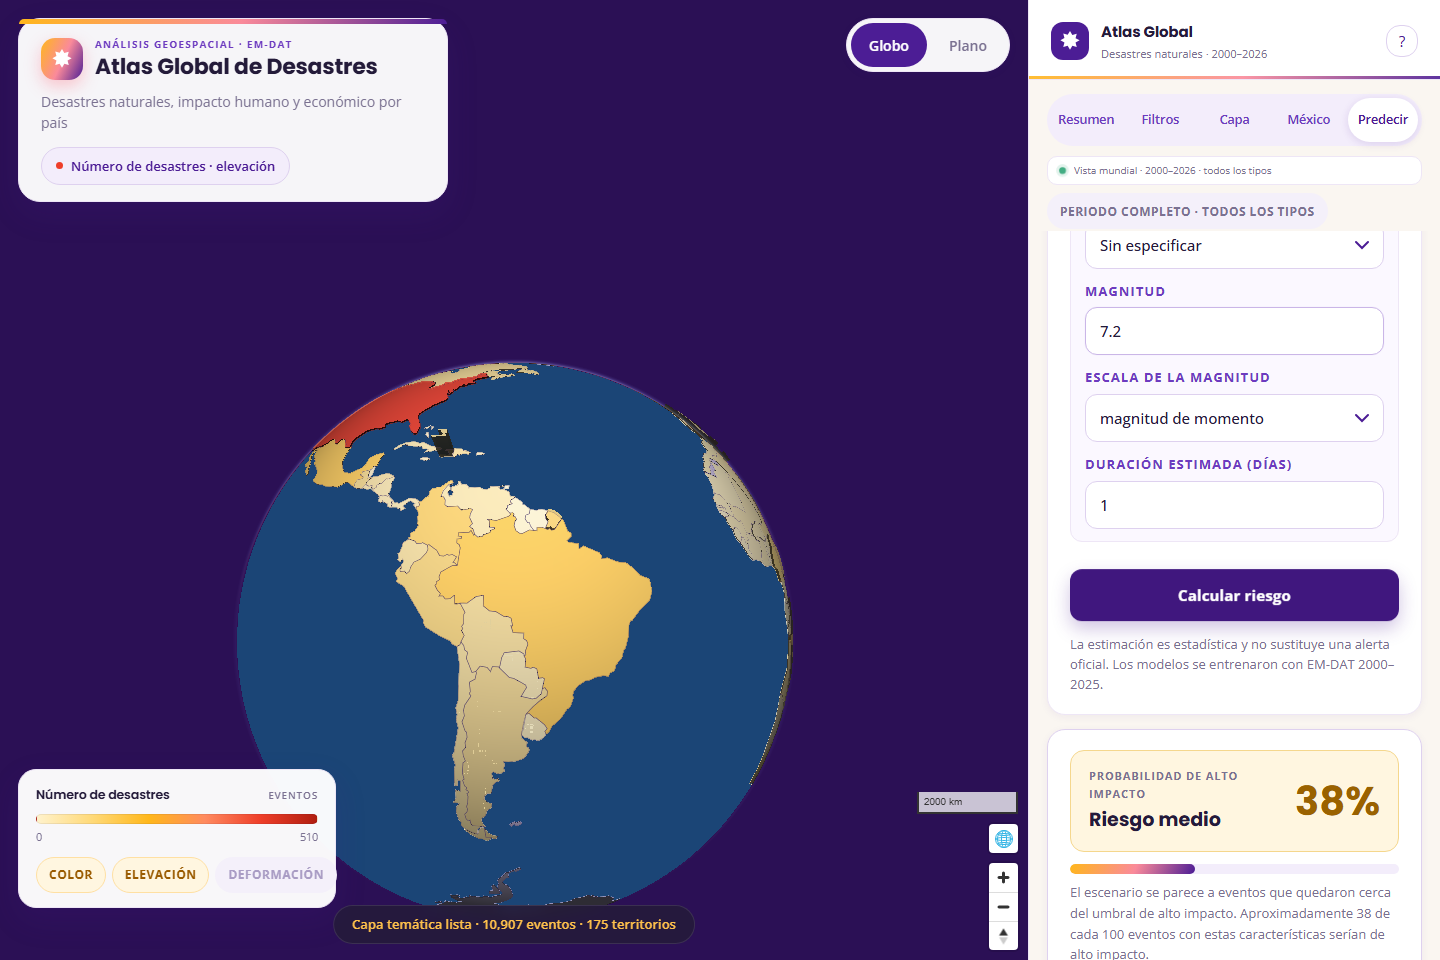

Vista móvil


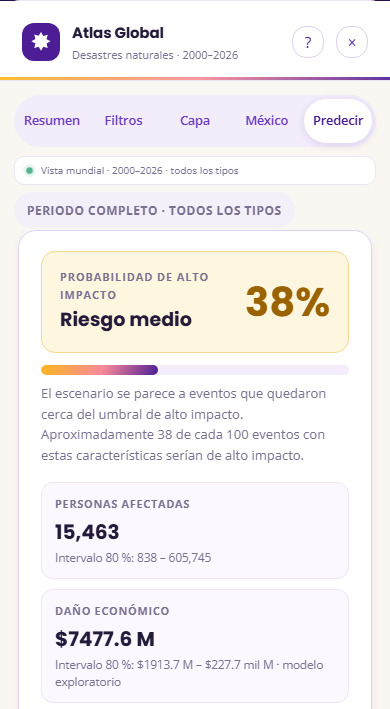

In [6]:
for nombre, titulo in [
    ("actividad13_prediccion_escritorio.png", "Vista de escritorio"),
    ("actividad13_prediccion_movil.png", "Vista móvil"),
]:
    ruta = GRAFICAS / nombre
    if ruta.exists():
        print(titulo)
        display(Image(filename=str(ruta), width=900))
    else:
        print(f"Falta la captura {ruta.relative_to(RAIZ)}")

## 6. Comprobaciones automáticas

La auditoría de interfaz y las pruebas de integridad verifican la pestaña,
los controles, el paquete exportado, la ausencia de fuga de información y la
inferencia sin conexión:

```bash
python -m src.validar_ui
python -m unittest discover -s tests -v
```

In [7]:
pruebas = {
    "HTML con pestaña": 'data-pestana="prediccion"' in (RAIZ / "app" / "index.html").read_text(encoding="utf-8"),
    "Script cargado": 'src="js/prediccion.js"' in (RAIZ / "app" / "index.html").read_text(encoding="utf-8"),
    "Sin peticiones externas": "https://" not in (RAIZ / "app" / "js" / "prediccion.js").read_text(encoding="utf-8"),
    "Recursos locales": (RAIZ / "app" / "vendor" / "maplibre").exists(),
    "Modelo incluido en Docker": "COPY app/" in (RAIZ / "Dockerfile").read_text(encoding="utf-8"),
}
display(pd.DataFrame([{"comprobacion": k, "resultado": "OK" if v else "REVISAR"} for k, v in pruebas.items()]))
assert all(pruebas.values())
print("La predicción está integrada y disponible sin conexión.")

,comprobacion,resultado
0,HTML con pestaña,OK
1,Script cargado,OK
2,Sin peticiones externas,OK
3,Recursos locales,OK
4,Modelo incluido en Docker,OK


La predicción está integrada y disponible sin conexión.


## Conclusión

* El paquete de modelos pesa cerca de **3 MB** y contiene todo lo necesario
  para predecir en el navegador, sin API ni peticiones externas.
* La inferencia de JavaScript coincide con Python con una diferencia menor a
  **0.000001**, así que las métricas y el ejemplo son auditables.
* La pestaña **Predecir** muestra la probabilidad, los afectados, el daño y
  los factores asociados, con advertencias claras sobre su alcance.
* La entrega en Docker incluye `app/modelos/`, por lo que la predicción
  funciona en cualquier equipo con Docker, incluso sin internet.